## **Incident Operations Python Analysis**


---



In [3]:

# ============================================================
# IT SERVICE MANAGEMENT — PYTHON DIAGNOSTIC ANALYSIS
# STEP 01: Load and Validate Source Datasets
# ============================================================

import io
import pandas as pd
from google.colab import files

# Upload both cleaned CSV files
uploaded = files.upload()

# Load incident-level dataset
incidents = pd.read_csv(
    io.BytesIO(uploaded["ITSM_Python_Incidents_Clean.csv"]),
    encoding="utf-8-sig",
    dtype={"number": "string"},
    low_memory=False
)

# Load event-level dataset
events = pd.read_csv(
    io.BytesIO(uploaded["ITSM_Python_Events_Clean.csv"]),
    encoding="utf-8-sig",
    dtype={"number": "string"},
    low_memory=False
)

# Display dataset dimensions
print("DATASET DIMENSIONS")
print("-" * 45)

print(
    f"Incidents: {incidents.shape[0]:,} rows, "
    f"{incidents.shape[1]} columns"
)

print(
    f"Events:    {events.shape[0]:,} rows, "
    f"{events.shape[1]} columns"
)

# Verify incident identifiers
print("\nIDENTIFIER VALIDATION")
print("-" * 45)

print(
    f"Unique incident IDs: "
    f"{incidents['number'].nunique():,}"
)

print(
    f"Unique incident IDs in events: "
    f"{events['number'].nunique():,}"
)

print(
    f"Duplicate incident IDs: "
    f"{incidents['number'].duplicated().sum():,}"
)

print(
    f"Missing event incident IDs: "
    f"{events['number'].isna().sum():,}"
)

print(
    f"Event IDs absent from incidents: "
    f"{len(set(events['number'].dropna()) - set(incidents['number'].dropna())):,}"
)


Saving ITSM_Python_Events_Clean.csv to ITSM_Python_Events_Clean.csv
Saving ITSM_Python_Incidents_Clean.csv to ITSM_Python_Incidents_Clean.csv
DATASET DIMENSIONS
---------------------------------------------
Incidents: 24,918 rows, 27 columns
Events:    141,712 rows, 41 columns

IDENTIFIER VALIDATION
---------------------------------------------
Unique incident IDs: 24,918
Unique incident IDs in events: 24,918
Duplicate incident IDs: 0
Missing event incident IDs: 0
Event IDs absent from incidents: 0


In [8]:

# ============================================================
# STEP 02: Validate Resolution Data Completeness
# ============================================================

resolved_at = (
    incidents["Resolved_At"]
    .astype("string")
    .str.strip()
)

has_resolution_date = (
    resolved_at.notna()
    & resolved_at.ne("")
)

durations = pd.to_numeric(
    incidents["Resolution_Duration_Minutes"],
    errors="coerce"
)

print("RESOLUTION DATA VALIDATION")
print("-" * 45)

print(f"Total incidents: {len(incidents):,}")
print(f"Valid resolution dates: {has_resolution_date.sum():,}")

print(
    f"Missing resolution dates: "
    f"{(~has_resolution_date).sum():,}"
)

print(
    f"Resolved incidents with zero-minute duration: "
    f"{((has_resolution_date) & (durations == 0)).sum():,}"
)



RESOLUTION DATA VALIDATION
---------------------------------------------
Total incidents: 24,918
Valid resolution dates: 23,362
Missing resolution dates: 1,556
Resolved incidents with zero-minute duration: 39


In [9]:

# ============================================================
# STEP 02B — Restore Validated Resolution Analysis Column
# ============================================================

import pandas as pd

# Identify incidents with a recorded resolution timestamp
resolved_text = (
    incidents["Resolved_At"]
    .astype("string")
    .str.strip()
)

missing_tokens = ["", "null", "none", "nan", "nat"]

has_resolution_date = (
    resolved_text.notna()
    & ~resolved_text.str.lower().isin(missing_tokens)
)

# Convert original durations to numeric values
durations = pd.to_numeric(
    incidents["Resolution_Duration_Minutes"],
    errors="coerce"
)

# Recreate the analysis column
incidents["Resolution_Duration_Analysis"] = (
    durations.where(
        has_resolution_date & durations.ge(0)
    )
)

# Validate the restored column
valid = incidents["Resolution_Duration_Analysis"].dropna()

print("RESOLUTION ANALYSIS COLUMN RESTORED")
print("-" * 45)
print(f"Valid durations: {len(valid):,}")
print(f"Missing durations: {incidents['Resolution_Duration_Analysis'].isna().sum():,}")
print(f"Median: {valid.median():,.2f} minutes")
print(f"P90: {valid.quantile(0.90):,.2f} minutes")

assert len(valid) == 23362, "Resolution count does not match SQL"
print("\nSTATUS: PASS")


RESOLUTION ANALYSIS COLUMN RESTORED
---------------------------------------------
Valid durations: 23,362
Missing durations: 1,556
Median: 1,326.00 minutes
P90: 22,892.90 minutes

STATUS: PASS


RESOLUTION-TIME DISTRIBUTION
-------------------------------------------------------
Valid incidents:       23,362
Median (minutes):      1,326.00
P90 (minutes):         22,892.90
Mean (minutes):        10,690.29
Minimum (minutes):     0.00
Maximum (minutes):     484,210.00
Median (hours):        22.10
P90 (days):            15.90

SQL RECONCILIATION
-------------------------------------------------------
Median: PASS
P90: PASS


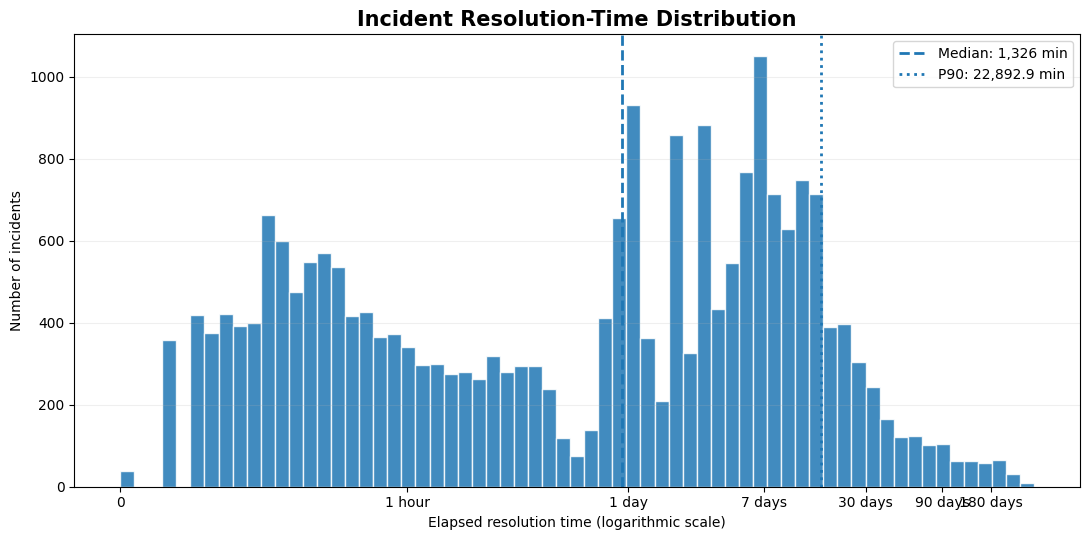

In [10]:

# ============================================================
# STEP 03 — Overall Resolution-Time Distribution
# Purpose: Profile resolution delays and identify the long tail
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Use the validated analysis column
resolution = pd.to_numeric(
    incidents["Resolution_Duration_Analysis"],
    errors="coerce"
).dropna()

# 2. Recheck data eligibility
assert len(resolution) == 23362, "Unexpected valid record count"
assert (resolution >= 0).all(), "Negative durations detected"

# 3. Calculate descriptive statistics
median_minutes = resolution.median()
p90_minutes = resolution.quantile(0.90, interpolation="linear")
mean_minutes = resolution.mean()

print("RESOLUTION-TIME DISTRIBUTION")
print("-" * 55)
print(f"Valid incidents:       {len(resolution):,}")
print(f"Median (minutes):      {median_minutes:,.2f}")
print(f"P90 (minutes):         {p90_minutes:,.2f}")
print(f"Mean (minutes):        {mean_minutes:,.2f}")
print(f"Minimum (minutes):     {resolution.min():,.2f}")
print(f"Maximum (minutes):     {resolution.max():,.2f}")
print(f"Median (hours):        {median_minutes / 60:,.2f}")
print(f"P90 (days):            {p90_minutes / 1440:,.2f}")

# 4. Compare with previously validated SQL results
print("\nSQL RECONCILIATION")
print("-" * 55)

print(
    "Median:",
    "PASS" if abs(median_minutes - 1326) < 0.01 else "REVIEW"
)

print(
    "P90:",
    "PASS" if abs(p90_minutes - 22892.90) < 0.01 else "REVIEW"
)

# 5. Plot the full distribution
# Log1p includes genuine zero-minute durations
log_resolution = np.log1p(resolution)

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.hist(
    log_resolution,
    bins=65,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    np.log1p(median_minutes),
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_minutes:,.0f} min"
)

ax.axvline(
    np.log1p(p90_minutes),
    linestyle=":",
    linewidth=2,
    label=f"P90: {p90_minutes:,.1f} min"
)

# Human-readable axis labels
time_ticks = [
    (0, "0"),
    (60, "1 hour"),
    (1440, "1 day"),
    (10080, "7 days"),
    (43200, "30 days"),
    (129600, "90 days"),
    (259200, "180 days"),
    (525600, "365 days")
]

visible_ticks = [
    (value, label)
    for value, label in time_ticks
    if value <= resolution.max()
]

ax.set_xticks(
    [np.log1p(value) for value, label in visible_ticks]
)

ax.set_xticklabels(
    [label for value, label in visible_ticks]
)

ax.set_title(
    "Incident Resolution-Time Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Elapsed resolution time (logarithmic scale)")
ax.set_ylabel("Number of incidents")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


LONG-TAIL RESOLUTION DIAGNOSTICS
-------------------------------------------------------
Mean      :    10,690.29 minutes (7.42 days)
Median    :     1,326.00 minutes (0.92 days)
P75       :     8,908.75 minutes (6.19 days)
P90       :    22,892.90 minutes (15.90 days)
P95       :    42,631.05 minutes (29.60 days)
P99       :   170,604.04 minutes (118.48 days)
Maximum   :   484,210.00 minutes (336.26 days)

RESOLUTION-TIME BANDS
-------------------------------------------------------
0–24 hours          :  12,072 ( 51.67%)
>24 hours–7 days    :   5,930 ( 25.38%)
>7–30 days          :   4,211 ( 18.02%)
>30 days            :   1,149 (  4.92%)

VALIDATION
-------------------------------------------------------
Band total: 23,362
Band reconciliation: PASS
Median reconciliation: PASS
P90 reconciliation: PASS


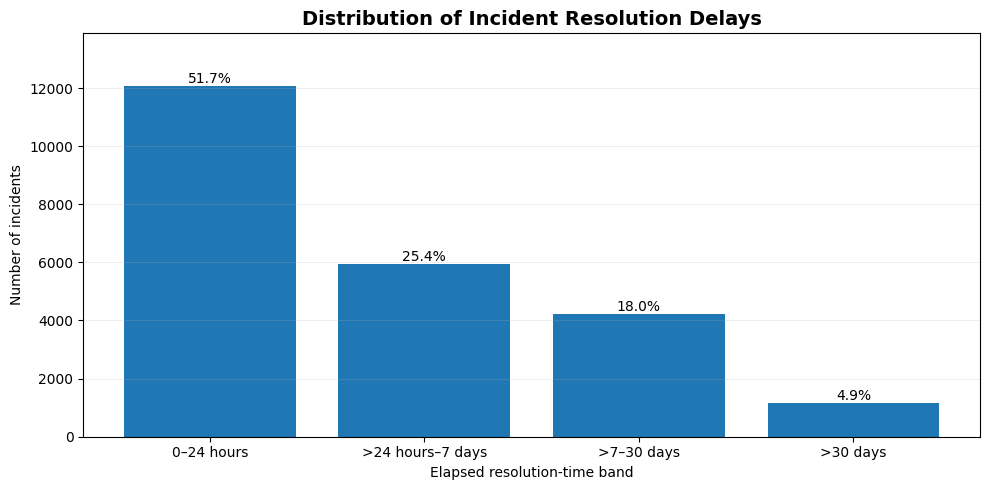

In [11]:

# ============================================================
# STEP 04 — Long-Tail Resolution Diagnostics
# Purpose: Identify prolonged incidents and delay severity
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Retrieve valid durations only
resolution = pd.to_numeric(
    incidents["Resolution_Duration_Analysis"],
    errors="coerce"
).dropna()

# Confirm the expected population
assert len(resolution) == 23362, "Unexpected record count"
assert np.isfinite(resolution).all(), "Non-finite values detected"
assert (resolution >= 0).all(), "Negative duration detected"

# 2. Calculate descriptive statistics
statistics = {
    "Mean": resolution.mean(),
    "Median": resolution.median(),
    "P75": resolution.quantile(0.75),
    "P90": resolution.quantile(0.90),
    "P95": resolution.quantile(0.95),
    "P99": resolution.quantile(0.99),
    "Maximum": resolution.max()
}

print("LONG-TAIL RESOLUTION DIAGNOSTICS")
print("-" * 55)

for name, minutes in statistics.items():
    print(
        f"{name:<10}: "
        f"{minutes:>12,.2f} minutes "
        f"({minutes / 1440:,.2f} days)"
    )

# 3. Group incidents into mutually exclusive delay bands
# Thresholds are descriptive, NOT verified SLA targets.

bands = {
    "0–24 hours": int(
        (resolution <= 1440).sum()
    ),
    ">24 hours–7 days": int(
        ((resolution > 1440) &
         (resolution <= 10080)).sum()
    ),
    ">7–30 days": int(
        ((resolution > 10080) &
         (resolution <= 43200)).sum()
    ),
    ">30 days": int(
        (resolution > 43200).sum()
    )
}

print("\nRESOLUTION-TIME BANDS")
print("-" * 55)

total = len(resolution)

for name, count in bands.items():
    percentage = (count / total) * 100
    print(
        f"{name:<20}: {count:>7,} "
        f"({percentage:>6.2f}%)"
    )

# 4. Validate the delay-band totals
assert sum(bands.values()) == total

print("\nVALIDATION")
print("-" * 55)
print(f"Band total: {sum(bands.values()):,}")
print("Band reconciliation: PASS")

print(
    "Median reconciliation:",
    "PASS" if abs(statistics["Median"] - 1326) < 0.01
    else "REVIEW"
)

print(
    "P90 reconciliation:",
    "PASS" if abs(statistics["P90"] - 22892.90) < 0.01
    else "REVIEW"
)

# 5. Visualise the delay bands
fig, ax = plt.subplots(figsize=(10, 5))

labels = list(bands.keys())
counts = list(bands.values())

bars = ax.bar(labels, counts)

for bar, count in zip(bars, counts):
    percentage = 100 * count / total

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Distribution of Incident Resolution Delays",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Number of incidents")
ax.set_xlabel("Elapsed resolution-time band")

ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [12]:

# ============================================================
# STEP 05 — Reassignment vs Resolution Time
# Purpose: Validate group differences and missing-data rates
# ============================================================

import numpy as np
import pandas as pd

# 1. Retrieve reassignment counts
reassignments = pd.to_numeric(
    incidents["Reassignment_Count"],
    errors="coerce"
)

# 2. Validate the reassignment field
assert reassignments.notna().all(), \
    "Missing or invalid reassignment counts detected"

assert (reassignments >= 0).all(), \
    "Negative reassignment counts detected"

assert (reassignments % 1 == 0).all(), \
    "Non-integer reassignment counts detected"

# 3. Create reassignment categories
incidents["Reassignment_Group"] = pd.Categorical(
    np.select(
        [
            reassignments.eq(0),
            reassignments.eq(1),
            reassignments.eq(2),
            reassignments.ge(3)
        ],
        ["0", "1", "2", "3+"],
        default="Invalid"
    ),
    categories=["0", "1", "2", "3+"],
    ordered=True
)

assert incidents["Reassignment_Group"].notna().all(), \
    "An incident was not assigned to a group"

# 4. Summarise resolution performance
summary = (
    incidents
    .groupby("Reassignment_Group", observed=True)
    .agg(
        total_incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        )
    )
)

# 5. Assess missing resolution durations
summary["missing_durations"] = (
    summary["total_incidents"]
    - summary["valid_durations"]
)

summary["missing_rate_pct"] = (
    summary["missing_durations"]
    / summary["total_incidents"] * 100
)

summary["median_days"] = (
    summary["median_minutes"] / 1440
)

# 6. Display results
print("REASSIGNMENT VS RESOLUTION TIME")
print("-" * 70)

print(
    summary.round(2).to_string()
)

# 7. Reconcile incident counts with SQL
expected_counts = {
    "0": 13549,
    "1": 6238,
    "2": 2283,
    "3+": 2848
}

print("\nSQL GROUP RECONCILIATION")
print("-" * 70)

for group, expected in expected_counts.items():
    actual = int(summary.loc[group, "total_incidents"])
    status = "PASS" if actual == expected else "REVIEW"

    print(
        f"Group {group}: {status} "
        f"(Python {actual:,}; SQL {expected:,})"
    )

# 8. Check dataset totals
assert summary["total_incidents"].sum() == 24918
assert summary["valid_durations"].sum() == 23362
assert summary["missing_durations"].sum() == 1556

print("\nOVERALL VALIDATION: PASS")


REASSIGNMENT VS RESOLUTION TIME
----------------------------------------------------------------------
                    total_incidents  valid_durations  median_minutes  p90_minutes  missing_durations  missing_rate_pct  median_days
Reassignment_Group                                                                                                                 
0                             13549            12003            41.0      12438.6               1546             11.41         0.03
1                              6238             6228          2523.0      21306.6                 10              0.16         1.75
2                              2283             2283          6178.0      36504.6                  0              0.00         4.29
3+                             2848             2848         11510.0      49187.7                  0              0.00         7.99

SQL GROUP RECONCILIATION
----------------------------------------------------------------------
Group 0:

In [13]:

# ============================================================
# STEP 06 — Kruskal-Wallis Statistical Test
# Purpose: Test resolution-time differences across
# four incident reassignment groups
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import kruskal

# 1. Define the four reassignment groups
group_labels = ["0", "1", "2", "3+"]

# 2. Retrieve valid resolution durations for each group
samples = []

for label in group_labels:
    values = pd.to_numeric(
        incidents.loc[
            incidents["Reassignment_Group"] == label,
            "Resolution_Duration_Analysis"
        ],
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    assert np.isfinite(values).all(), \
        f"Invalid values found in group {label}"

    samples.append(values)

# 3. Validate the statistical sample
sample_sizes = [len(sample) for sample in samples]
total_valid = sum(sample_sizes)

assert total_valid == 23362, \
    "Statistical sample does not match validated SQL records"

print("STATISTICAL SAMPLE VALIDATION")
print("-" * 55)

for label, size in zip(group_labels, sample_sizes):
    print(f"Group {label}: {size:,} valid incidents")

print(f"Total: {total_valid:,}")

# 4. Run the Kruskal-Wallis H test
h_statistic, p_value = kruskal(*samples)

# 5. Calculate an approximate rank-based effect size
# Epsilon-squared is an omnibus effect-size estimate.
n = total_valid
k = len(samples)

epsilon_squared = max(
    0,
    (h_statistic - k + 1) / (n - k)
)

# 6. Report statistical results
print("\nKRUSKAL-WALLIS TEST RESULTS")
print("-" * 55)

print(f"H statistic:       {h_statistic:,.4f}")
print(f"P-value:           {p_value:.6e}")
print(f"Epsilon-squared:   {epsilon_squared:.4f}")

# 7. Interpret significance
alpha = 0.05

print("\nSTATISTICAL DECISION")
print("-" * 55)

if p_value < alpha:
    print("RESULT: Statistically significant")
    print("DECISION: Reject the null hypothesis")
    print("INTERPRETATION: At least one group differs.")
else:
    print("RESULT: Not statistically significant")
    print("DECISION: Do not reject the null hypothesis")

print("\nIMPORTANT LIMITATIONS")
print("-" * 55)
print("Observational association, not proof of causation.")
print("Missing durations are unevenly distributed.")
print("Other incident characteristics may confound results.")


STATISTICAL SAMPLE VALIDATION
-------------------------------------------------------
Group 0: 12,003 valid incidents
Group 1: 6,228 valid incidents
Group 2: 2,283 valid incidents
Group 3+: 2,848 valid incidents
Total: 23,362

KRUSKAL-WALLIS TEST RESULTS
-------------------------------------------------------
H statistic:       6,493.5491
P-value:           0.000000e+00
Epsilon-squared:   0.2779

STATISTICAL DECISION
-------------------------------------------------------
RESULT: Statistically significant
DECISION: Reject the null hypothesis
INTERPRETATION: At least one group differs.

IMPORTANT LIMITATIONS
-------------------------------------------------------
Observational association, not proof of causation.
Missing durations are unevenly distributed.
Other incident characteristics may confound results.


In [14]:

# ============================================================
# STEP 07 — Pairwise Reassignment Group Comparisons
# Purpose: Identify which groups differ in resolution time
# Method: Mann-Whitney U + Holm multiple-test correction
# ============================================================

import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1. Define reassignment groups
group_labels = ["0", "1", "2", "3+"]

# 2. Retrieve valid durations for each group
group_data = {}

for label in group_labels:
    values = pd.to_numeric(
        incidents.loc[
            incidents["Reassignment_Group"] == label,
            "Resolution_Duration_Analysis"
        ],
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    assert len(values) > 0, f"Empty group: {label}"
    assert np.isfinite(values).all()

    group_data[label] = values

assert sum(map(len, group_data.values())) == 23362

# 3. Run the six pairwise comparisons
results = []

for group_a, group_b in combinations(group_labels, 2):

    a = group_data[group_a]
    b = group_data[group_b]

    u_stat, p_value = mannwhitneyu(
        a,
        b,
        alternative="two-sided",
        method="asymptotic"
    )

    # Signed rank-biserial correlation:
    # Positive means group A tends to have longer durations
    # Negative means group B tends to have longer durations
    rank_biserial = (
        2 * u_stat / (len(a) * len(b))
    ) - 1

    results.append({
        "Comparison": f"{group_a} vs {group_b}",
        "N_A": len(a),
        "N_B": len(b),
        "Median_A_Min": np.median(a),
        "Median_B_Min": np.median(b),
        "U_Statistic": u_stat,
        "P_Raw": p_value,
        "Rank_Biserial": rank_biserial
    })

# 4. Convert to a DataFrame
pairwise = pd.DataFrame(results)

# 5. Correct for multiple comparisons using Holm
reject, p_adjusted, _, _ = multipletests(
    pairwise["P_Raw"].to_numpy(),
    alpha=0.05,
    method="holm"
)

pairwise["P_Holm"] = p_adjusted
pairwise["Significant"] = reject

# 6. Display results
print("PAIRWISE REASSIGNMENT COMPARISONS")
print("-" * 80)

display(
    pairwise[
        [
            "Comparison",
            "N_A",
            "N_B",
            "Median_A_Min",
            "Median_B_Min",
            "P_Holm",
            "Rank_Biserial",
            "Significant"
        ]
    ].round(4)
)

# 7. Summary validation
print("\nVALIDATION")
print("-" * 50)
print(f"Number of comparisons: {len(pairwise)}")
print(f"Significant comparisons: {reject.sum()}")
print(f"Non-significant comparisons: {(~reject).sum()}")

assert len(pairwise) == 6
assert pairwise["Rank_Biserial"].between(-1, 1).all()

print("Six comparisons completed: PASS")


PAIRWISE REASSIGNMENT COMPARISONS
--------------------------------------------------------------------------------


,Comparison,N_A,N_B,Median_A_Min,Median_B_Min,P_Holm,Rank_Biserial,Significant
0,0 vs 1,12003,6228,41.0,2523.0,0.0,-0.4418,True
1,0 vs 2,12003,2283,41.0,6178.0,0.0,-0.6432,True
2,0 vs 3+,12003,2848,41.0,11510.0,0.0,-0.7491,True
3,1 vs 2,6228,2283,2523.0,6178.0,0.0,-0.2807,True
4,1 vs 3+,6228,2848,2523.0,11510.0,0.0,-0.4964,True
5,2 vs 3+,2283,2848,6178.0,11510.0,0.0,-0.2531,True



VALIDATION
--------------------------------------------------
Number of comparisons: 6
Significant comparisons: 6
Non-significant comparisons: 0
Six comparisons completed: PASS


In [15]:

# ============================================================
# STEP 08 — Moderate-Priority Reassignment Diagnostics
# Purpose: Check whether the reassignment association
# persists within the largest priority category
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import kruskal

# 1. Identify Moderate-priority incidents
priority = (
    incidents["Initial_Priority"]
    .astype("string")
    .str.strip()
)

moderate_mask = priority.str.contains(
    r"\bModerate\b",
    case=False,
    na=False,
    regex=True
)

moderate = incidents.loc[moderate_mask].copy()

# 2. Validate population against SQL
print("MODERATE-PRIORITY POPULATION")
print("-" * 60)

print(f"Total incidents: {len(moderate):,}")

valid_count = (
    moderate["Resolution_Duration_Analysis"]
    .notna()
    .sum()
)

missing_count = len(moderate) - valid_count

print(f"Valid durations: {valid_count:,}")
print(f"Missing durations: {missing_count:,}")

assert len(moderate) == 23681, \
    "Moderate-priority count differs from SQL"

assert valid_count == 22225, \
    "Valid resolution count differs from SQL"

assert missing_count == 1456, \
    "Missing duration count differs from SQL"

# 3. Compare reassignment groups
summary_moderate = (
    moderate
    .groupby("Reassignment_Group", observed=True)
    .agg(
        incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        )
    )
    .reindex(["0", "1", "2", "3+"])
)

summary_moderate["missing_durations"] = (
    summary_moderate["incidents"]
    - summary_moderate["valid_durations"]
)

summary_moderate["missing_rate_pct"] = (
    100 * summary_moderate["missing_durations"]
    / summary_moderate["incidents"]
)

summary_moderate["median_days"] = (
    summary_moderate["median_minutes"] / 1440
)

print("\nMODERATE-PRIORITY GROUP COMPARISON")
print("-" * 60)

print(summary_moderate.round(2).to_string())

# 4. Prepare valid samples for statistical testing
group_labels = ["0", "1", "2", "3+"]

samples = [
    moderate.loc[
        moderate["Reassignment_Group"] == label,
        "Resolution_Duration_Analysis"
    ].dropna().to_numpy(dtype=float)
    for label in group_labels
]

assert all(len(sample) > 0 for sample in samples)
assert sum(len(sample) for sample in samples) == 22225

# 5. Run Kruskal-Wallis within Moderate priority
h_statistic, p_value = kruskal(*samples)

n = sum(len(sample) for sample in samples)
k = len(samples)

epsilon_squared = max(
    0,
    (h_statistic - k + 1) / (n - k)
)

print("\nMODERATE-PRIORITY KRUSKAL-WALLIS TEST")
print("-" * 60)

print(f"H statistic: {h_statistic:,.4f}")

if p_value == 0:
    print("P-value: Below floating-point precision")
else:
    print(f"P-value: {p_value:.6e}")

print(f"Epsilon-squared: {epsilon_squared:.4f}")

print("\nSTATISTICAL DECISION")

if p_value < 0.05:
    print("Reject H0: At least one group differs.")
else:
    print("Do not reject H0.")

print("\nVALIDATION: PASS")


MODERATE-PRIORITY POPULATION
------------------------------------------------------------
Total incidents: 23,681
Valid durations: 22,225
Missing durations: 1,456

MODERATE-PRIORITY GROUP COMPARISON
------------------------------------------------------------
                    incidents  valid_durations  median_minutes  p90_minutes  missing_durations  missing_rate_pct  median_days
Reassignment_Group                                                                                                           
0                       12879            11433            39.0      11561.0               1446             11.23         0.03
1                        5941             5931          2572.0      21200.0                 10              0.17         1.79
2                        2154             2154          6675.5      37577.4                  0              0.00         4.64
3+                       2707             2707         11547.0      49974.2                  0              0.

In [16]:

# ============================================================
# STEP 09 — Handling Activity vs Resolution Time
# Purpose: Investigate associations between the number
# of recorded events and incident-resolution delays
# ============================================================

import numpy as np
import pandas as pd

# 1. Convert recorded handling-event counts to numeric
event_counts = pd.to_numeric(
    incidents["Event_Count"],
    errors="coerce"
)

# 2. Validate the underlying values
assert event_counts.notna().all(), \
    "Missing event counts detected"

assert (event_counts >= 2).all(), \
    "Unexpected event count below 2"

assert (event_counts % 1 == 0).all(), \
    "Non-integer event counts detected"

# 3. Create handling-event categories
group_labels = ["2–3", "4–6", "7–10", "11+"]

incidents["Handling_Event_Group"] = pd.cut(
    event_counts,
    bins=[1, 3, 6, 10, np.inf],
    labels=group_labels,
    include_lowest=True
)

# 4. Calculate group-level resolution statistics
event_summary = (
    incidents
    .groupby("Handling_Event_Group", observed=True)
    .agg(
        total_incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        )
    )
    .reindex(group_labels)
)

# 5. Calculate missing-data measures
event_summary["missing_durations"] = (
    event_summary["total_incidents"]
    - event_summary["valid_durations"]
)

event_summary["missing_rate_pct"] = (
    100 * event_summary["missing_durations"]
    / event_summary["total_incidents"]
)

event_summary["median_days"] = (
    event_summary["median_minutes"] / 1440
)

# 6. Print the summary
print("HANDLING ACTIVITY VS RESOLUTION TIME")
print("-" * 75)

print(event_summary.round(2).to_string())

# 7. Reconcile incident group counts with SQL
expected_counts = {
    "2–3": 8227,
    "4–6": 9374,
    "7–10": 5012,
    "11+": 2305
}

print("\nSQL GROUP RECONCILIATION")
print("-" * 75)

for group, expected in expected_counts.items():
    actual = int(
        event_summary.loc[group, "total_incidents"]
    )

    status = (
        "PASS" if actual == expected else "REVIEW"
    )

    print(
        f"Group {group}: {status} "
        f"(Python {actual:,}; SQL {expected:,})"
    )

# 8. Validate overall totals
assert event_summary["total_incidents"].sum() == 24918
assert event_summary["valid_durations"].sum() == 23362
assert event_summary["missing_durations"].sum() == 1556

print("\nOVERALL VALIDATION: PASS")


HANDLING ACTIVITY VS RESOLUTION TIME
---------------------------------------------------------------------------
                      total_incidents  valid_durations  median_minutes  p90_minutes  missing_durations  missing_rate_pct  median_days
Handling_Event_Group                                                                                                                 
2–3                              8227             6674            13.0        915.1               1553             18.88         0.01
4–6                              9374             9371          1227.0      19326.0                  3              0.03         0.85
7–10                             5012             5012          7119.0      33341.9                  0              0.00         4.94
11+                              2305             2305         16009.0      61663.0                  0              0.00        11.12

SQL GROUP RECONCILIATION
---------------------------------------------------------

In [17]:

# ============================================================
# STEP 10 — Handling Activity: Kruskal-Wallis Test
# Purpose: Test differences in resolution-time distributions
# across the four handling-event groups
# ============================================================

import numpy as np
from scipy.stats import kruskal

# 1. Define the handling-event groups
group_labels = ["2–3", "4–6", "7–10", "11+"]

# 2. Retrieve valid resolution durations
samples = []

print("STATISTICAL SAMPLE VALIDATION")
print("-" * 55)

for label in group_labels:

    values = (
        incidents.loc[
            incidents["Handling_Event_Group"] == label,
            "Resolution_Duration_Analysis"
        ]
        .dropna()
        .to_numpy(dtype=float)
    )

    assert len(values) > 0, f"Empty group: {label}"
    assert np.isfinite(values).all(), \
        f"Invalid duration in group {label}"

    samples.append(values)

    print(f"Group {label}: {len(values):,} valid incidents")

# 3. Validate total sample
n = sum(len(sample) for sample in samples)
k = len(samples)

print(f"\nTotal valid incidents: {n:,}")

assert n == 23362, \
    "Sample count does not match SQL"

# 4. Run Kruskal-Wallis test
h_statistic, p_value = kruskal(*samples)

# 5. Calculate omnibus effect size
epsilon_squared = max(
    0,
    (h_statistic - k + 1) / (n - k)
)

# 6. Report results
print("\nHANDLING-ACTIVITY KRUSKAL-WALLIS TEST")
print("-" * 55)

print(f"H statistic:     {h_statistic:,.4f}")

if p_value == 0:
    print("P-value:         Below floating-point precision")
else:
    print(f"P-value:         {p_value:.6e}")

print(f"Epsilon-squared: {epsilon_squared:.4f}")

# 7. Statistical decision
print("\nSTATISTICAL DECISION")
print("-" * 55)

if p_value < 0.05:
    print("RESULT: Statistically significant")
    print("DECISION: Reject H0")
    print("At least one handling-event group differs.")
else:
    print("RESULT: Not statistically significant")
    print("DECISION: Do not reject H0")

# 8. Display missingness for interpretation
print("\nMISSING-DURATION CHECK")
print("-" * 55)

for label in group_labels:
    row = event_summary.loc[label]

    print(
        f"{label}: "
        f"{int(row['missing_durations']):,} missing "
        f"({row['missing_rate_pct']:.2f}%)"
    )

print("\nVALIDATION: PASS")


STATISTICAL SAMPLE VALIDATION
-------------------------------------------------------
Group 2–3: 6,674 valid incidents
Group 4–6: 9,371 valid incidents
Group 7–10: 5,012 valid incidents
Group 11+: 2,305 valid incidents

Total valid incidents: 23,362

HANDLING-ACTIVITY KRUSKAL-WALLIS TEST
-------------------------------------------------------
H statistic:     11,261.7714
P-value:         Below floating-point precision
Epsilon-squared: 0.4820

STATISTICAL DECISION
-------------------------------------------------------
RESULT: Statistically significant
DECISION: Reject H0
At least one handling-event group differs.

MISSING-DURATION CHECK
-------------------------------------------------------
2–3: 1,553 missing (18.88%)
4–6: 3 missing (0.03%)
7–10: 0 missing (0.00%)
11+: 0 missing (0.00%)

VALIDATION: PASS


In [18]:

# STEP 10B — Display Statistical Results Only

print("HANDLING ACTIVITY — FINAL RESULTS")
print("-" * 45)

print(f"H statistic: {h_statistic:,.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Epsilon-squared: {epsilon_squared:.4f}")

print("\nMISSING DURATIONS BY EVENT GROUP")

print(
    event_summary[
        ["valid_durations",
         "missing_durations",
         "missing_rate_pct"]
    ].round(2).to_string()
)

print("\nRESULTS READY FOR REVIEW")


HANDLING ACTIVITY — FINAL RESULTS
---------------------------------------------
H statistic: 11,261.7714
P-value: 0.000000e+00
Epsilon-squared: 0.4820

MISSING DURATIONS BY EVENT GROUP
                      valid_durations  missing_durations  missing_rate_pct
Handling_Event_Group                                                      
2–3                              6674               1553             18.88
4–6                              9371                  3              0.03
7–10                             5012                  0              0.00
11+                              2305                  0              0.00

RESULTS READY FOR REVIEW


In [19]:

# ============================================================
# STEP 11 — Reassignment and Handling Activity Overlap
# Purpose: Determine whether high reassignment frequency
# and high handling-event volume occur together
# ============================================================

import pandas as pd

# 1. Create a cross-tabulation of the two indicators
overlap = pd.crosstab(
    incidents["Reassignment_Group"],
    incidents["Handling_Event_Group"]
)

# 2. Apply the established category order
overlap = overlap.reindex(
    index=["0", "1", "2", "3+"],
    columns=["2–3", "4–6", "7–10", "11+"],
    fill_value=0
)

print("REASSIGNMENT × HANDLING ACTIVITY")
print("-" * 65)
print(overlap.to_string())

# 3. Calculate percentages within reassignment groups
row_percentages = (
    overlap.div(overlap.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("\nROW PERCENTAGES (%)")
print("-" * 65)
print(row_percentages.to_string())

# 4. Calculate the key high-complexity overlap
high_overlap = int(
    overlap.loc["3+", ["7–10", "11+"]].sum()
)

high_reassignment_total = int(
    overlap.loc["3+"].sum()
)

overlap_percentage = (
    100 * high_overlap / high_reassignment_total
)

print("\nKEY OVERLAP FINDING")
print("-" * 65)

print(
    f"Incidents with 3+ reassignments and 7+ events: "
    f"{high_overlap:,}"
)

print(
    f"All incidents with 3+ reassignments: "
    f"{high_reassignment_total:,}"
)

print(
    f"Percentage with 7+ events: "
    f"{overlap_percentage:.2f}%"
)

# 5. Validate against previously confirmed SQL results
checks = {
    "Total incidents": int(overlap.values.sum()) == 24918,
    "3+ reassignment count": high_reassignment_total == 2848,
    "High-overlap incidents": high_overlap == 2737,
    "Handling-event counts": (
        overlap.sum(axis=0).tolist()
        == [8227, 9374, 5012, 2305]
    ),
    "Reassignment counts": (
        overlap.sum(axis=1).tolist()
        == [13549, 6238, 2283, 2848]
    )
}

print("\nSQL RECONCILIATION")
print("-" * 65)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

assert all(checks.values()), \
    "One or more results differ from SQL"

print("\nOVERALL VALIDATION: PASS")


REASSIGNMENT × HANDLING ACTIVITY
-----------------------------------------------------------------
Handling_Event_Group   2–3   4–6  7–10   11+
Reassignment_Group                          
0                     7849  4643   923   134
1                      378  3885  1696   279
2                        0   735  1183   365
3+                       0   111  1210  1527

ROW PERCENTAGES (%)
-----------------------------------------------------------------
Handling_Event_Group    2–3    4–6   7–10    11+
Reassignment_Group                              
0                     57.93  34.27   6.81   0.99
1                      6.06  62.28  27.19   4.47
2                      0.00  32.19  51.82  15.99
3+                     0.00   3.90  42.49  53.62

KEY OVERLAP FINDING
-----------------------------------------------------------------
Incidents with 3+ reassignments and 7+ events: 2,737
All incidents with 3+ reassignments: 2,848
Percentage with 7+ events: 96.10%

SQL RECONCILIATION
-------------

In [20]:

# ============================================================
# STEP 12 — Combined Workflow Performance Diagnostics
# Purpose: Examine resolution times when reassignment
# frequency and handling-event volume are considered together
# ============================================================

import numpy as np
import pandas as pd

# 1. Retrieve the two validated operational indicators
reassign = pd.to_numeric(
    incidents["Reassignment_Count"],
    errors="coerce"
)

handling = pd.to_numeric(
    incidents["Event_Count"],
    errors="coerce"
)

# Check for missing or invalid values
assert reassign.notna().all()
assert handling.notna().all()
assert (reassign >= 0).all()
assert (handling >= 2).all()

# 2. Define four combined workflow groups
group_order = [
    "0–2 reassign | 2–6 events",
    "0–2 reassign | 7+ events",
    "3+ reassign | 2–6 events",
    "3+ reassign | 7+ events"
]

conditions = [
    (reassign <= 2) & (handling <= 6),
    (reassign <= 2) & (handling >= 7),
    (reassign >= 3) & (handling <= 6),
    (reassign >= 3) & (handling >= 7)
]

incidents["Workflow_Group"] = pd.Categorical(
    np.select(
        conditions,
        group_order,
        default="Unclassified"
    ),
    categories=group_order + ["Unclassified"],
    ordered=True
)

assert (
    incidents["Workflow_Group"] == "Unclassified"
).sum() == 0

# 3. Calculate resolution-performance statistics
workflow_summary = (
    incidents
    .groupby("Workflow_Group", observed=True)
    .agg(
        total_incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        )
    )
    .reindex(group_order)
)

# 4. Calculate missingness and duration conversions
workflow_summary["missing_durations"] = (
    workflow_summary["total_incidents"]
    - workflow_summary["valid_durations"]
)

workflow_summary["missing_rate_pct"] = (
    100 * workflow_summary["missing_durations"]
    / workflow_summary["total_incidents"]
)

workflow_summary["median_days"] = (
    workflow_summary["median_minutes"] / 1440
)

workflow_summary["p90_days"] = (
    workflow_summary["p90_minutes"] / 1440
)

# 5. Display the complete analysis
print("COMBINED WORKFLOW RESOLUTION ANALYSIS")
print("-" * 85)
print(workflow_summary.round(2).to_string())

# 6. Reconcile population sizes with SQL
expected_counts = [17490, 4580, 111, 2737]

print("\nSQL GROUP VALIDATION")
print("-" * 60)

for label, expected in zip(group_order, expected_counts):
    actual = int(
        workflow_summary.loc[label, "total_incidents"]
    )

    print(
        f"{label}: "
        f"{'PASS' if actual == expected else 'REVIEW'}"
    )

# 7. Reconcile resolution medians with SQL
expected_medians = [85, 7999.5, 3264, 11657]

print("\nMEDIAN RECONCILIATION")
print("-" * 60)

for label, expected in zip(group_order, expected_medians):
    actual = workflow_summary.loc[label, "median_minutes"]

    print(
        f"{label}: "
        f"{'PASS' if abs(actual - expected) < 0.01 else 'REVIEW'}"
    )

# 8. Confirm overall totals
assert workflow_summary["total_incidents"].sum() == 24918
assert workflow_summary["valid_durations"].sum() == 23362
assert workflow_summary["missing_durations"].sum() == 1556

assert (
    workflow_summary["total_incidents"].tolist()
    == expected_counts
), "Population counts differ from SQL"

print("\nOVERALL POPULATION VALIDATION: PASS")


COMBINED WORKFLOW RESOLUTION ANALYSIS
-------------------------------------------------------------------------------------
                           total_incidents  valid_durations  median_minutes  p90_minutes  missing_durations  missing_rate_pct  median_days  p90_days
Workflow_Group                                                                                                                                      
0–2 reassign | 2–6 events            17490            15934            85.0      11638.6               1556               8.9         0.06      8.08
0–2 reassign | 7+ events              4580             4580          7999.5      38332.9                  0               0.0         5.56     26.62
3+ reassign | 2–6 events               111              111          3264.0      31955.0                  0               0.0         2.27     22.19
3+ reassign | 7+ events               2737             2737         11657.0      50142.6                  0               0.0      

In [21]:

# ============================================================
# STEP 13 — Event-Level Routing Data Validation
# Purpose: Prepare the event history for support-team
# transfer and routing-loop analysis
# ============================================================

import pandas as pd

# 1. Check required columns
required_columns = [
    "number",
    "CSV_Row",
    "Event_Order",
    "sys_updated_at",
    "assignment_group"
]

missing_columns = [
    col for col in required_columns
    if col not in events.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

# 2. Create a working dataset
# The original events DataFrame remains unchanged.
routing_events = events[required_columns].copy()

# 3. Standardise incident identifiers
routing_events["number"] = (
    routing_events["number"]
    .astype("string")
    .str.strip()
)

# 4. Standardise assignment-group values
groups = (
    routing_events["assignment_group"]
    .astype("string")
    .str.strip()
)

missing_tokens = {
    "", "?", "nan", "none",
    "null", "nat", "n/a", "<na>"
}

group_missing = (
    groups.isna()
    | groups.str.lower().isin(missing_tokens)
).fillna(True)

routing_events["Assignment_Group_Clean"] = (
    groups.mask(group_missing)
)

# 5. Prepare ordering fields
routing_events["CSV_Row_Numeric"] = pd.to_numeric(
    routing_events["CSV_Row"],
    errors="coerce"
)

routing_events["Event_Order_Numeric"] = pd.to_numeric(
    routing_events["Event_Order"],
    errors="coerce"
)

# 6. Validate records and identifiers
total_events = len(routing_events)

unique_incidents = (
    routing_events["number"].nunique()
)

known_groups = int(
    routing_events["Assignment_Group_Clean"]
    .notna().sum()
)

unknown_groups = total_events - known_groups

unique_csv_rows = (
    routing_events["CSV_Row_Numeric"].nunique()
)

incidents_with_group = (
    routing_events.loc[
        routing_events["Assignment_Group_Clean"].notna(),
        "number"
    ].nunique()
)

incidents_without_group = (
    unique_incidents - incidents_with_group
)

# 7. Display results
print("EVENT-LEVEL ROUTING DATA VALIDATION")
print("-" * 60)

print(f"Total events:                  {total_events:,}")
print(f"Unique incidents:              {unique_incidents:,}")
print(f"Known assignment-group events: {known_groups:,}")
print(f"Unknown assignment groups:     {unknown_groups:,}")
print(f"Incidents without any group:   {incidents_without_group:,}")
print(f"Unique CSV_Row identifiers:    {unique_csv_rows:,}")

print("\nEVENT ORDERING CHECK")
print("-" * 60)

print(
    "Missing CSV_Row values:",
    routing_events["CSV_Row_Numeric"].isna().sum()
)

print(
    "Missing Event_Order values:",
    routing_events["Event_Order_Numeric"].isna().sum()
)

# 8. Reconcile against SQL
checks = {
    "Event count": total_events == 141712,
    "Incident IDs": unique_incidents == 24918,
    "Known assignment groups": known_groups == 127499,
    "Unknown assignment groups": unknown_groups == 14213,
    "Incidents without group": incidents_without_group == 373,
    "Unique event row IDs": unique_csv_rows == 141712
}

print("\nSQL RECONCILIATION")
print("-" * 60)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


EVENT-LEVEL ROUTING DATA VALIDATION
------------------------------------------------------------
Total events:                  141,712
Unique incidents:              24,918
Known assignment-group events: 127,499
Unknown assignment groups:     14,213
Incidents without any group:   373
Unique CSV_Row identifiers:    141,712

EVENT ORDERING CHECK
------------------------------------------------------------
Missing CSV_Row values: 0
Missing Event_Order values: 0

SQL RECONCILIATION
------------------------------------------------------------
Event count: PASS
Incident IDs: PASS
Known assignment groups: PASS
Unknown assignment groups: PASS
Incidents without group: PASS
Unique event row IDs: PASS

OVERALL VALIDATION: PASS


In [22]:

# ============================================================
# STEP 14 — Event Chronology Validation
# Purpose: Verify that event ordering is suitable for
# reconstructing support-team routing histories
# ============================================================

import pandas as pd

# 1. Create a separate working copy
chronology = routing_events.copy()

# 2. Parse event timestamps
chronology["Updated_Timestamp"] = pd.to_datetime(
    chronology["sys_updated_at"],
    format="mixed",
    errors="coerce",
    utc=True
)

# 3. Sort chronologically within each incident
# Event_Order is the primary ordering field.
# CSV_Row is the secondary tie-breaker.
chronology = chronology.sort_values(
    by=[
        "number",
        "Event_Order_Numeric",
        "CSV_Row_Numeric"
    ],
    kind="stable"
).reset_index(drop=True)

# 4. Check timestamp completeness
missing_timestamps = int(
    chronology["Updated_Timestamp"].isna().sum()
)

# 5. Check whether Event_Order repeats within an incident
duplicate_event_orders = int(
    chronology.duplicated(
        subset=["number", "Event_Order_Numeric"],
        keep=False
    ).sum()
)

# 6. Check event-order numbering
order_summary = (
    chronology.groupby("number")
    ["Event_Order_Numeric"]
    .agg(["min", "max", "count", "nunique"])
)

starts_at_one = int(
    (order_summary["min"] == 1).sum()
)

nonsequential_incidents = int(
    (
        (order_summary["min"] != 1)
        | (order_summary["max"] != order_summary["count"])
        | (order_summary["nunique"] != order_summary["count"])
    ).sum()
)

# 7. Compare adjacent event timestamps
chronology["Previous_Timestamp"] = (
    chronology.groupby("number")["Updated_Timestamp"]
    .shift(1)
)

comparable_pairs = (
    chronology["Updated_Timestamp"].notna()
    & chronology["Previous_Timestamp"].notna()
)

backward_mask = (
    comparable_pairs
    & (
        chronology["Updated_Timestamp"]
        < chronology["Previous_Timestamp"]
    )
)

tied_mask = (
    comparable_pairs
    & (
        chronology["Updated_Timestamp"]
        == chronology["Previous_Timestamp"]
    )
)

backward_events = int(backward_mask.sum())
tied_timestamps = int(tied_mask.sum())
comparable_count = int(comparable_pairs.sum())

# 8. Display results
print("EVENT CHRONOLOGY VALIDATION")
print("-" * 60)

print(f"Total event records:           {len(chronology):,}")
print(f"Unique incidents:              {chronology['number'].nunique():,}")
print(f"Missing/unparseable timestamps: {missing_timestamps:,}")
print(f"Duplicate Event_Order rows:    {duplicate_event_orders:,}")
print(f"Incidents starting at order 1: {starts_at_one:,}")
print(f"Nonsequential incident orders: {nonsequential_incidents:,}")

print("\nCHRONOLOGICAL CONSISTENCY")
print("-" * 60)

print(f"Comparable adjacent time pairs: {comparable_count:,}")
print(f"Backward timestamps:            {backward_events:,}")
print(f"Equal adjacent timestamps:      {tied_timestamps:,}")

# 9. Show examples if any timestamps run backwards
if backward_events > 0:
    print("\nEXAMPLES OF BACKWARD TIMESTAMPS")

    display(
        chronology.loc[
            backward_mask,
            [
                "number",
                "Event_Order_Numeric",
                "CSV_Row_Numeric",
                "Previous_Timestamp",
                "Updated_Timestamp"
            ]
        ].head(10)
    )

# 10. Reconcile known source counts
print("\nSOURCE RECONCILIATION")
print("-" * 60)

print(
    "Event count:",
    "PASS" if len(chronology) == 141712 else "REVIEW"
)

print(
    "Incident count:",
    "PASS"
    if chronology["number"].nunique() == 24918
    else "REVIEW"
)

# 11. Assess readiness for routing reconstruction
print("\nCHRONOLOGY ASSESSMENT")
print("-" * 60)

if (
    missing_timestamps == 0
    and duplicate_event_orders == 0
    and nonsequential_incidents == 0
    and backward_events == 0
):
    print("STATUS: PASS")
    print("Event ordering passed the chronology checks.")
else:
    print("STATUS: REVIEW")
    print("Investigate ordering issues before reconstructing routes.")

print(
    "\nNote: Equal timestamps are allowed, but their "
    "within-timestamp order may not be independently verifiable."
)


EVENT CHRONOLOGY VALIDATION
------------------------------------------------------------
Total event records:           141,712
Unique incidents:              24,918
Missing/unparseable timestamps: 0
Duplicate Event_Order rows:    0
Incidents starting at order 1: 1
Nonsequential incident orders: 24,917

CHRONOLOGICAL CONSISTENCY
------------------------------------------------------------
Comparable adjacent time pairs: 116,794
Backward timestamps:            0
Equal adjacent timestamps:      14,118

SOURCE RECONCILIATION
------------------------------------------------------------
Event count: PASS
Incident count: PASS

CHRONOLOGY ASSESSMENT
------------------------------------------------------------
STATUS: REVIEW
Investigate ordering issues before reconstructing routes.

Note: Equal timestamps are allowed, but their within-timestamp order may not be independently verifiable.


In [23]:

# ============================================================
# STEP 15 — Reconstruct Observed Support-Team Transitions
# Purpose: Identify changes between consecutive recorded
# assignment groups and reconcile with SQL findings
# ============================================================

import pandas as pd

# 1. Work from the prepared chronology dataset
ordered_events = chronology.sort_values(
    [
        "number",
        "Event_Order_Numeric",
        "CSV_Row_Numeric"
    ],
    kind="stable"
).copy()

# 2. Retrieve the preceding event's assignment group
ordered_events["Previous_Group"] = (
    ordered_events
    .groupby("number", sort=False)["Assignment_Group_Clean"]
    .shift(1)
)

# 3. Retrieve the preceding event's timestamp
ordered_events["Previous_Timestamp"] = (
    ordered_events
    .groupby("number", sort=False)["Updated_Timestamp"]
    .shift(1)
)

# 4. Identify adjacent event pairs with two known groups
comparable = (
    ordered_events["Previous_Group"].notna()
    & ordered_events["Assignment_Group_Clean"].notna()
)

# 5. Identify observed changes between known groups
group_changed = (
    ordered_events["Previous_Group"]
    .ne(ordered_events["Assignment_Group_Clean"])
    .fillna(False)
)

transition_mask = comparable & group_changed

# 6. Create a transition-level dataset
transitions = ordered_events.loc[
    transition_mask,
    [
        "number",
        "Previous_Group",
        "Assignment_Group_Clean",
        "Previous_Timestamp",
        "Updated_Timestamp"
    ]
].copy()

transitions = transitions.rename(
    columns={
        "Previous_Group": "From_Group",
        "Assignment_Group_Clean": "To_Group"
    }
)

# 7. Calculate key operational metrics
comparable_pairs = int(comparable.sum())
total_transitions = len(transitions)
incidents_with_transitions = transitions["number"].nunique()

transition_rate = (
    100 * total_transitions / comparable_pairs
    if comparable_pairs else 0
)

# 8. Identify transitions sharing identical timestamps
tied_transitions = int(
    (
        transitions["Previous_Timestamp"]
        == transitions["Updated_Timestamp"]
    ).sum()
)

# 9. Display findings
print("SUPPORT-TEAM TRANSITION ANALYSIS")
print("-" * 65)

print(f"Comparable adjacent pairs:  {comparable_pairs:,}")
print(f"Observed group changes:     {total_transitions:,}")
print(f"Incidents with changes:     {incidents_with_transitions:,}")
print(f"Group-change rate:          {transition_rate:.2f}%")
print(f"Changes with tied times:    {tied_transitions:,}")

# 10. Identify the most frequent directional transfers
top_transitions = (
    transitions
    .groupby(["From_Group", "To_Group"])
    .agg(
        transition_count=("number", "size"),
        distinct_incidents=("number", "nunique")
    )
    .sort_values(
        "transition_count",
        ascending=False
    )
    .head(10)
)

print("\nTOP 10 OBSERVED GROUP TRANSFERS")
print("-" * 65)

print(top_transitions.to_string())

# 11. Reconcile results with SQL
checks = {
    "Comparable pairs": comparable_pairs == 101409,
    "Observed changes": total_transitions == 17914,
    "Incidents with changes": incidents_with_transitions == 9224
}

print("\nSQL RECONCILIATION")
print("-" * 65)

for name, passed in checks.items():
    print(
        f"{name}: "
        f"{'PASS' if passed else 'REVIEW'}"
    )

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


SUPPORT-TEAM TRANSITION ANALYSIS
-----------------------------------------------------------------
Comparable adjacent pairs:  101,409
Observed group changes:     17,914
Incidents with changes:     9,224
Group-change rate:          17.67%
Changes with tied times:    4,216

TOP 10 OBSERVED GROUP TRANSFERS
-----------------------------------------------------------------
                     transition_count  distinct_incidents
From_Group To_Group                                      
Group 20   Group 70              1080                 926
Group 70   Group 39               974                 867
           Group 20               790                 674
Group 39   Group 70               432                 379
Group 54   Group 70               395                 354
Group 70   Group 25               367                 354
Group 56   Group 70               260                 226
Group 66   Group 70               245                 218
Group 70   Group 24               245           

In [24]:

# ============================================================
# STEP 16 — Detect Repeated Support-Team Routing Returns
# Purpose: Identify observed A -> B -> A routing patterns
# without crossing missing assignment-group records
# ============================================================

import pandas as pd

# 1. Reuse the validated chronological event sequence
route_data = ordered_events.sort_values(
    ["number", "Event_Order_Numeric", "CSV_Row_Numeric"],
    kind="stable"
).copy()

# 2. Separate continuous sequences at missing groups
missing_group = route_data["Assignment_Group_Clean"].isna()

route_data["Route_Segment"] = (
    missing_group.groupby(route_data["number"])
    .cumsum()
)

known = route_data.loc[~missing_group].copy()

# 3. Collapse consecutive repeated group observations
segment_keys = ["number", "Route_Segment"]

previous_group = (
    known.groupby(segment_keys, sort=False)
    ["Assignment_Group_Clean"].shift(1)
)

new_visit = (
    known["Assignment_Group_Clean"]
    .ne(previous_group)
    .fillna(True)
)

visits = known.loc[new_visit].copy()

# 4. Find the next two group visits within each segment
visit_groups = visits.groupby(segment_keys, sort=False)

visits["Next_Group"] = (
    visit_groups["Assignment_Group_Clean"].shift(-1)
)

visits["Third_Group"] = (
    visit_groups["Assignment_Group_Clean"].shift(-2)
)

visits["Next_Time"] = (
    visit_groups["Updated_Timestamp"].shift(-1)
)

visits["Third_Time"] = (
    visit_groups["Updated_Timestamp"].shift(-2)
)

# 5. Identify A -> B -> A patterns
return_mask = (
    visits["Next_Group"].notna()
    & visits["Third_Group"].notna()
    & visits["Assignment_Group_Clean"]
        .eq(visits["Third_Group"]).fillna(False)
    & visits["Assignment_Group_Clean"]
        .ne(visits["Next_Group"]).fillna(False)
)

routing_returns = visits.loc[return_mask].copy()

routing_returns["Pattern"] = (
    routing_returns["Assignment_Group_Clean"].astype(str)
    + " -> "
    + routing_returns["Next_Group"].astype(str)
    + " -> "
    + routing_returns["Third_Group"].astype(str)
)

# 6. Summarise patterns and distinct incidents
return_summary = (
    routing_returns
    .groupby("Pattern")
    .agg(
        pattern_count=("number", "size"),
        distinct_incidents=("number", "nunique")
    )
    .sort_values("pattern_count", ascending=False)
)

print("TOP 10 OBSERVED ROUTING RETURNS")
print("-" * 75)
print(return_summary.head(10).to_string())

print("\nTOTAL ROUTING-RETURN OBSERVATIONS")
print("-" * 75)
print(f"Return patterns: {len(routing_returns):,}")
print(
    "Incidents with at least one return:",
    f"{routing_returns['number'].nunique():,}"
)

# 7. Identify returns affected by timestamp ties
tied_returns = (
    routing_returns["Updated_Timestamp"]
        .eq(routing_returns["Next_Time"])
    | routing_returns["Next_Time"]
        .eq(routing_returns["Third_Time"])
)

print(
    "Returns involving tied visit timestamps:",
    f"{int(tied_returns.sum()):,}"
)

# 8. Compare four leading patterns with SQL
benchmarks = {
    "Group 70 -> Group 20 -> Group 70": 337,
    "Group 70 -> Group 39 -> Group 70": 259,
    "Group 20 -> Group 70 -> Group 20": 179,
    "Group 39 -> Group 70 -> Group 39": 131
}

print("\nSQL ROUTING-RETURN COMPARISON")
print("-" * 75)

for pattern, expected in benchmarks.items():
    actual = (
        int(return_summary.loc[pattern, "pattern_count"])
        if pattern in return_summary.index
        else 0
    )

    status = "PASS" if actual == expected else "REVIEW"

    print(
        f"{status}: {pattern} "
        f"| Python={actual:,}, SQL={expected:,}"
    )


TOP 10 OBSERVED ROUTING RETURNS
---------------------------------------------------------------------------
                                  pattern_count  distinct_incidents
Pattern                                                            
Group 70 -> Group 20 -> Group 70            337                 271
Group 70 -> Group 39 -> Group 70            259                 233
Group 20 -> Group 70 -> Group 20            179                 135
Group 39 -> Group 70 -> Group 39            131                 111
Group 70 -> Group 54 -> Group 70             98                  90
Group 70 -> Group 69 -> Group 70             80                  76
Group 9 -> Group 25 -> Group 9               62                  51
Group 70 -> Group 66 -> Group 70             56                  49
Group 25 -> Group 9 -> Group 25              55                  37
Group 70 -> Group 55 -> Group 70             54                  53

TOTAL ROUTING-RETURN OBSERVATIONS
-----------------------------------------

In [25]:

# ============================================================
# STEP 17 — Routing Returns vs Resolution Performance
# Purpose: Compare Moderate-priority incidents with and
# without observed A -> B -> A routing returns
# ============================================================

import numpy as np
import pandas as pd

# 1. Count observed routing returns per incident
return_counts = (
    routing_returns
    .groupby("number")
    .size()
)

print("ROUTING RETURN SOURCE VALIDATION")
print("-" * 65)

print(f"Total return occurrences: {return_counts.sum():,}")
print(f"Incidents with returns: {len(return_counts):,}")

assert return_counts.sum() == 3231
assert len(return_counts) == 1963

# 2. Identify Moderate-priority incidents
priority = (
    incidents["Initial_Priority"]
    .astype("string")
    .str.strip()
)

moderate_mask = priority.str.contains(
    r"\bModerate\b",
    case=False,
    regex=True,
    na=False
)

moderate_routes = incidents.loc[moderate_mask].copy()

assert len(moderate_routes) == 23681

# 3. Join routing-return counts at incident level
# One row per incident is preserved.
moderate_routes["Routing_Return_Count"] = (
    moderate_routes["number"]
    .astype("string")
    .str.strip()
    .map(return_counts)
    .fillna(0)
    .astype(int)
)

moderate_routes["Routing_Return_Status"] = np.where(
    moderate_routes["Routing_Return_Count"] > 0,
    "Observed return",
    "No observed return"
)

# 4. Prepare numeric reassignment counts
moderate_routes["Reassignments_Numeric"] = pd.to_numeric(
    moderate_routes["Reassignment_Count"],
    errors="coerce"
)

# 5. Calculate summary statistics
route_summary = (
    moderate_routes
    .groupby("Routing_Return_Status")
    .agg(
        incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        ),
        avg_reassignments=(
            "Reassignments_Numeric", "mean"
        ),
        return_occurrences=(
            "Routing_Return_Count", "sum"
        )
    )
    .reindex([
        "No observed return",
        "Observed return"
    ])
)

# 6. Calculate missing data and time conversions
route_summary["missing_durations"] = (
    route_summary["incidents"]
    - route_summary["valid_durations"]
)

route_summary["missing_rate_pct"] = (
    100 * route_summary["missing_durations"]
    / route_summary["incidents"]
)

route_summary["median_days"] = (
    route_summary["median_minutes"] / 1440
)

route_summary["p90_days"] = (
    route_summary["p90_minutes"] / 1440
)

# 7. Display results
print("\nMODERATE-PRIORITY ROUTING RETURN ANALYSIS")
print("-" * 80)

print(route_summary.round(2).to_string())

# 8. Reconcile against SQL
expected = {
    "No observed return": {
        "incidents": 21818,
        "valid_durations": 20362,
        "missing_durations": 1456,
        "median_minutes": 882,
        "p90_minutes": 19944.8
    },
    "Observed return": {
        "incidents": 1863,
        "valid_durations": 1863,
        "missing_durations": 0,
        "median_minutes": 10805,
        "p90_minutes": 81530
    }
}

print("\nSQL RECONCILIATION")
print("-" * 80)

all_checks = []

for group, metrics in expected.items():
    for metric, target in metrics.items():

        actual = route_summary.loc[group, metric]

        passed = abs(actual - target) < 0.01
        all_checks.append(passed)

        print(
            f"{group} | {metric}: "
            f"{'PASS' if passed else 'REVIEW'}"
        )

# 9. Validate total population and missingness
assert route_summary["incidents"].sum() == 23681
assert route_summary["valid_durations"].sum() == 22225
assert route_summary["missing_durations"].sum() == 1456

print("\nOVERALL VALIDATION:",
      "PASS" if all(all_checks) else "REVIEW")


ROUTING RETURN SOURCE VALIDATION
-----------------------------------------------------------------
Total return occurrences: 3,231
Incidents with returns: 1,963

MODERATE-PRIORITY ROUTING RETURN ANALYSIS
--------------------------------------------------------------------------------
                       incidents  valid_durations  median_minutes  p90_minutes  avg_reassignments  return_occurrences  missing_durations  missing_rate_pct  median_days  p90_days
Routing_Return_Status                                                                                                                                                            
No observed return         21818            20362           882.0      19944.8               0.67                   0               1456              6.67         0.61     13.85
Observed return             1863             1863         10805.0      81530.0               4.11                3056                  0              0.00         7.50     56.62

SQ

In [26]:

# ============================================================
# STEP 18 — Routing Returns: Mann-Whitney U Test
# Purpose: Test whether Moderate-priority incident
# resolution times differ by observed routing-return status
# ============================================================

import numpy as np
from scipy.stats import mannwhitneyu

# 1. Retrieve valid durations for both groups
no_return = (
    moderate_routes.loc[
        moderate_routes["Routing_Return_Status"]
        == "No observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

with_return = (
    moderate_routes.loc[
        moderate_routes["Routing_Return_Status"]
        == "Observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

# 2. Validate samples
n_a = len(no_return)
n_b = len(with_return)

assert n_a == 20362, "No-return sample differs from SQL"
assert n_b == 1863, "Return sample differs from SQL"
assert n_a + n_b == 22225

assert np.isfinite(no_return).all()
assert np.isfinite(with_return).all()

print("STATISTICAL SAMPLE VALIDATION")
print("-" * 60)

print(f"No observed return: {n_a:,}")
print(f"Observed return:    {n_b:,}")
print(f"Total valid cases:  {n_a + n_b:,}")

# 3. Run the two-sided Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    no_return,
    with_return,
    alternative="two-sided",
    method="asymptotic"
)

# 4. Calculate rank-biserial correlation
# Negative values mean the observed-return group
# generally has longer resolution durations.
rank_biserial = (
    2 * u_statistic / (n_a * n_b)
) - 1

# 5. Calculate descriptive medians
median_no_return = np.median(no_return)
median_with_return = np.median(with_return)

median_ratio = (
    median_with_return / median_no_return
    if median_no_return > 0 else np.nan
)

# 6. Print statistical results
print("\nMANN-WHITNEY U TEST RESULTS")
print("-" * 60)

print(f"U statistic:       {u_statistic:,.2f}")

if p_value == 0:
    print("P-value:           Below floating-point precision")
else:
    print(f"P-value:           {p_value:.6e}")

print(f"Rank-biserial:     {rank_biserial:.4f}")

print("\nDESCRIPTIVE COMPARISON")
print("-" * 60)

print(f"No-return median:   {median_no_return:,.2f} minutes")
print(f"Return median:      {median_with_return:,.2f} minutes")
print(f"Median ratio:       {median_ratio:.2f}x")

# 7. Statistical decision
print("\nSTATISTICAL DECISION")
print("-" * 60)

if p_value < 0.05:
    print("RESULT: Statistically significant")
    print("DECISION: Reject H0")
    print("Resolution-time distributions differ.")
else:
    print("RESULT: Not statistically significant")
    print("DECISION: Do not reject H0")

# 8. Reconcile descriptive results
checks = {
    "Sample total": n_a + n_b == 22225,
    "No-return median": abs(median_no_return - 882) < 0.01,
    "Return median": abs(median_with_return - 10805) < 0.01,
    "Effect-size bounds": -1 <= rank_biserial <= 1
}

print("\nVALIDATION")
print("-" * 60)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


STATISTICAL SAMPLE VALIDATION
------------------------------------------------------------
No observed return: 20,362
Observed return:    1,863
Total valid cases:  22,225

MANN-WHITNEY U TEST RESULTS
------------------------------------------------------------
U statistic:       8,128,727.50
P-value:           Below floating-point precision
Rank-biserial:     -0.5714

DESCRIPTIVE COMPARISON
------------------------------------------------------------
No-return median:   882.00 minutes
Return median:      10,805.00 minutes
Median ratio:       12.25x

STATISTICAL DECISION
------------------------------------------------------------
RESULT: Statistically significant
DECISION: Reject H0
Resolution-time distributions differ.

VALIDATION
------------------------------------------------------------
Sample total: PASS
No-return median: PASS
Return median: PASS
Effect-size bounds: PASS

OVERALL VALIDATION: PASS


In [27]:

# ============================================================
# STEP 19 — Routing Returns Within Similar Handling Activity
# Purpose: Compare Moderate-priority incidents with 7–10
# recorded handling events, by observed routing-return status
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# 1. Select Moderate-priority incidents with 7–10 events
event_count = pd.to_numeric(
    moderate_routes["Event_Count"],
    errors="coerce"
)

comparison = moderate_routes.loc[
    event_count.between(7, 10, inclusive="both")
].copy()

# 2. Validate incident-level population
assert comparison["number"].is_unique, \
    "Duplicate incident IDs detected"

assert len(comparison) > 0, \
    "No incidents found in this event-count category"

# 3. Summarise both routing-return groups
summary_19 = (
    comparison
    .groupby("Routing_Return_Status")
    .agg(
        incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        ),
        avg_event_count=("Event_Count", "mean"),
        avg_reassignments=("Reassignment_Count", "mean")
    )
    .reindex(["No observed return", "Observed return"])
)

summary_19["missing_durations"] = (
    summary_19["incidents"]
    - summary_19["valid_durations"]
)

summary_19["median_days"] = (
    summary_19["median_minutes"] / 1440
)

print("MODERATE PRIORITY — 7–10 HANDLING EVENTS")
print("-" * 75)
print(summary_19.round(2).to_string())

# 4. Prepare the two independent statistical samples
no_return = (
    comparison.loc[
        comparison["Routing_Return_Status"] ==
        "No observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

with_return = (
    comparison.loc[
        comparison["Routing_Return_Status"] ==
        "Observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

n_a = len(no_return)
n_b = len(with_return)

assert n_a > 0 and n_b > 0, \
    "Both groups must contain valid observations"

assert np.isfinite(no_return).all()
assert np.isfinite(with_return).all()

# 5. Run two-sided Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    no_return,
    with_return,
    alternative="two-sided",
    method="asymptotic"
)

# 6. Calculate rank-biserial effect size
rank_biserial = (
    2 * u_statistic / (n_a * n_b)
) - 1

# 7. Display statistical results
print("\nMANN-WHITNEY U — WITHIN 7–10 EVENTS")
print("-" * 75)

print(f"No-return valid cases:  {n_a:,}")
print(f"Return valid cases:     {n_b:,}")
print(f"U statistic:            {u_statistic:,.2f}")

if p_value == 0:
    print("P-value:                Below floating-point precision")
else:
    print(f"P-value:                {p_value:.6e}")

print(f"Rank-biserial:          {rank_biserial:.4f}")

print(
    f"No-return median:       "
    f"{np.median(no_return):,.2f} minutes"
)

print(
    f"Return median:          "
    f"{np.median(with_return):,.2f} minutes"
)

print("\nSTATISTICAL DECISION")
print("-" * 75)

if p_value < 0.05:
    print("Statistically significant difference")
    print("Reject H0")
else:
    print("No statistically significant difference detected")
    print("Do not reject H0")

# 8. Verify internal consistency
print("\nVALIDATION")
print("-" * 75)

checks = {
    "Unique incident IDs": comparison["number"].is_unique,
    "Both groups populated": n_a > 0 and n_b > 0,
    "Valid counts reconcile":
        n_a + n_b == summary_19["valid_durations"].sum(),
    "Missing counts reconcile":
        int(summary_19["missing_durations"].sum())
        == len(comparison) - n_a - n_b,
    "Effect-size bounds": -1 <= rank_biserial <= 1
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


MODERATE PRIORITY — 7–10 HANDLING EVENTS
---------------------------------------------------------------------------
                       incidents  valid_durations  median_minutes  p90_minutes  avg_event_count  avg_reassignments  missing_durations  median_days
Routing_Return_Status                                                                                                                             
No observed return          3965             3965          7133.0      30188.2             8.09               1.41                  0         4.95
Observed return              769              769          7326.0      68244.8             8.49               2.94                  0         5.09

MANN-WHITNEY U — WITHIN 7–10 EVENTS
---------------------------------------------------------------------------
No-return valid cases:  3,965
Return valid cases:     769
U statistic:            1,439,252.50
P-value:                1.393622e-02
Rank-biserial:          -0.0559
No-return median: 

In [28]:

# ============================================================
# STEP 20 — Routing Returns Among High-Handling Incidents
# Purpose: Compare Moderate-priority incidents with 11+
# recorded events by observed routing-return status
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# 1. Select Moderate-priority incidents with 11+ events
event_count_20 = pd.to_numeric(
    moderate_routes["Event_Count"],
    errors="coerce"
)

high_handling = moderate_routes.loc[
    event_count_20 >= 11
].copy()

# 2. Prepare numeric measures
high_handling["Events_Numeric"] = pd.to_numeric(
    high_handling["Event_Count"],
    errors="coerce"
)

high_handling["Reassignments_Numeric"] = pd.to_numeric(
    high_handling["Reassignment_Count"],
    errors="coerce"
)

# 3. Validate incident-level dataset
assert high_handling["number"].is_unique
assert len(high_handling) > 0
assert high_handling["Events_Numeric"].ge(11).all()

# 4. Calculate descriptive statistics
group_order = [
    "No observed return",
    "Observed return"
]

summary_20 = (
    high_handling
    .groupby("Routing_Return_Status")
    .agg(
        incidents=("number", "size"),
        valid_durations=(
            "Resolution_Duration_Analysis", "count"
        ),
        median_minutes=(
            "Resolution_Duration_Analysis", "median"
        ),
        p90_minutes=(
            "Resolution_Duration_Analysis",
            lambda x: x.quantile(0.90)
        ),
        avg_events=("Events_Numeric", "mean"),
        avg_reassignments=("Reassignments_Numeric", "mean")
    )
    .reindex(group_order)
)

summary_20["missing_durations"] = (
    summary_20["incidents"]
    - summary_20["valid_durations"]
)

summary_20["median_days"] = (
    summary_20["median_minutes"] / 1440
)

summary_20["p90_days"] = (
    summary_20["p90_minutes"] / 1440
)

print("MODERATE PRIORITY — 11+ HANDLING EVENTS")
print("-" * 80)
print(summary_20.round(2).to_string())

# 5. Prepare statistical samples
a = (
    high_handling.loc[
        high_handling["Routing_Return_Status"]
        == "No observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

b = (
    high_handling.loc[
        high_handling["Routing_Return_Status"]
        == "Observed return",
        "Resolution_Duration_Analysis"
    ]
    .dropna()
    .to_numpy(dtype=float)
)

n_a, n_b = len(a), len(b)

assert n_a > 0 and n_b > 0
assert np.isfinite(a).all() and np.isfinite(b).all()

# 6. Run the Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    a,
    b,
    alternative="two-sided",
    method="asymptotic"
)

# 7. Calculate effect size
rank_biserial = (
    2 * u_statistic / (n_a * n_b)
) - 1

# 8. Calculate median difference and ratio
median_a = np.median(a)
median_b = np.median(b)

median_difference = median_b - median_a

median_ratio = (
    median_b / median_a
    if median_a > 0
    else np.nan
)

# 9. Print statistical results
print("\nMANN-WHITNEY U — WITHIN 11+ EVENTS")
print("-" * 80)

print(f"No-return valid cases: {n_a:,}")
print(f"Return valid cases:    {n_b:,}")
print(f"U statistic:          {u_statistic:,.2f}")
print(f"P-value:              {p_value:.6e}")
print(f"Rank-biserial:        {rank_biserial:.4f}")
print(f"No-return median:     {median_a:,.2f} minutes")
print(f"Return median:        {median_b:,.2f} minutes")
print(f"Median difference:    {median_difference:,.2f} minutes")
print(f"Median ratio:         {median_ratio:.2f}x")

print("\nSTATISTICAL DECISION")
print("-" * 80)

if p_value < 0.05:
    print("Statistically significant difference")
    print("Reject H0")
else:
    print("No statistically significant difference detected")
    print("Do not reject H0")

# 10. Validate internal consistency
checks = {
    "Unique incident IDs":
        high_handling["number"].is_unique,
    "Both groups populated":
        n_a > 0 and n_b > 0,
    "Valid counts reconcile":
        n_a + n_b == summary_20["valid_durations"].sum(),
    "Missing counts reconcile":
        int(summary_20["missing_durations"].sum())
        == len(high_handling) - n_a - n_b,
    "Effect-size bounds":
        -1 <= rank_biserial <= 1
}

print("\nVALIDATION")
print("-" * 80)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


MODERATE PRIORITY — 11+ HANDLING EVENTS
--------------------------------------------------------------------------------
                       incidents  valid_durations  median_minutes  p90_minutes  avg_events  avg_reassignments  missing_durations  median_days  p90_days
Routing_Return_Status                                                                                                                                  
No observed return          1227             1227         14658.0      48656.6       13.50               2.89                  0        10.18     33.79
Observed return              941              941         18463.0      97791.0       15.38               5.37                  0        12.82     67.91

MANN-WHITNEY U — WITHIN 11+ EVENTS
--------------------------------------------------------------------------------
No-return valid cases: 1,227
Return valid cases:    941
U statistic:          506,291.00
P-value:              8.851621e-07
Rank-biserial:        -0.1230


In [29]:

# ============================================================
# STEP 21 — Predictor Overlap and Multicollinearity
# Purpose: Assess overlap before multivariable modelling
# Population: Moderate-priority incidents with valid durations
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# 1. Select the validated analysis population
model_data = moderate_routes.loc[
    moderate_routes["Resolution_Duration_Analysis"].notna(),
    [
        "number",
        "Event_Count",
        "Reassignment_Count",
        "Routing_Return_Status",
        "Resolution_Duration_Analysis"
    ]
].copy()

# 2. Prepare numeric predictors
model_data["Event_Count"] = pd.to_numeric(
    model_data["Event_Count"],
    errors="coerce"
)

model_data["Reassignment_Count"] = pd.to_numeric(
    model_data["Reassignment_Count"],
    errors="coerce"
)

model_data["Has_Routing_Return"] = (
    model_data["Routing_Return_Status"]
    .eq("Observed return")
    .astype(int)
)

# 3. Validate the population
assert len(model_data) == 22225
assert model_data["number"].is_unique

assert model_data[
    ["Event_Count", "Reassignment_Count"]
].notna().all().all()

assert model_data["Event_Count"].ge(2).all()
assert model_data["Reassignment_Count"].ge(0).all()

return_count = int(
    model_data["Has_Routing_Return"].sum()
)

assert return_count == 1863

print("MODEL POPULATION VALIDATION")
print("-" * 60)
print(f"Valid Moderate incidents: {len(model_data):,}")
print(f"With observed return:     {return_count:,}")
print(f"Without observed return:  {len(model_data)-return_count:,}")

# 4. Calculate rank-based correlations
correlation_columns = [
    "Event_Count",
    "Reassignment_Count",
    "Has_Routing_Return"
]

correlations = (
    model_data[correlation_columns]
    .corr(method="spearman")
)

print("\nSPEARMAN CORRELATION MATRIX")
print("-" * 60)
print(correlations.round(4).to_string())

# 5. Prepare predictors for VIF calculation
# Log transform reduces the scale imbalance for event counts.
model_data["Log_Event_Count"] = np.log1p(
    model_data["Event_Count"]
)

predictors = model_data[
    [
        "Log_Event_Count",
        "Reassignment_Count",
        "Has_Routing_Return"
    ]
].astype(float)

# 6. Calculate variance inflation factors
X = sm.add_constant(
    predictors,
    has_constant="add"
)

vif_results = pd.DataFrame({
    "Predictor": predictors.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(1, X.shape[1])
    ]
})

print("\nMULTICOLLINEARITY DIAGNOSTICS")
print("-" * 60)
print(vif_results.round(3).to_string(index=False))

# 7. Check integrity
checks = {
    "Correct population": len(model_data) == 22225,
    "Unique incident records": model_data["number"].is_unique,
    "Correct return count": return_count == 1863,
    "Valid correlation matrix":
        np.isfinite(correlations.to_numpy()).all(),
    "Finite VIF values":
        np.isfinite(vif_results["VIF"]).all()
}

print("\nVALIDATION")
print("-" * 60)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


MODEL POPULATION VALIDATION
------------------------------------------------------------
Valid Moderate incidents: 22,225
With observed return:     1,863
Without observed return:  20,362

SPEARMAN CORRELATION MATRIX
------------------------------------------------------------
                    Event_Count  Reassignment_Count  Has_Routing_Return
Event_Count              1.0000              0.7201              0.3922
Reassignment_Count       0.7201              1.0000              0.4735
Has_Routing_Return       0.3922              0.4735              1.0000

MULTICOLLINEARITY DIAGNOSTICS
------------------------------------------------------------
         Predictor   VIF
   Log_Event_Count 2.148
Reassignment_Count 2.602
Has_Routing_Return 1.529

VALIDATION
------------------------------------------------------------
Correct population: PASS
Unique incident records: PASS
Correct return count: PASS
Valid correlation matrix: PASS
Finite VIF values: PASS

OVERALL VALIDATION: PASS


In [30]:

# ============================================================
# STEP 22 — Multivariable Incident Resolution Diagnostics
# Purpose: Examine routing-return associations conditional
# on recorded handling activity and reassignment frequency
#
# Method: OLS regression with HC3 robust standard errors
# Scope: Observational diagnostic, not causal estimation
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

# 1. Use the validated Step 21 analysis population
diagnostic = model_data.copy()

# 2. Validate required columns
required = [
    "number",
    "Resolution_Duration_Analysis",
    "Log_Event_Count",
    "Reassignment_Count",
    "Has_Routing_Return"
]

assert all(col in diagnostic.columns for col in required)

assert len(diagnostic) == 22225
assert diagnostic["number"].is_unique
assert diagnostic["Has_Routing_Return"].sum() == 1863

# 3. Prepare the resolution-time outcome
duration = pd.to_numeric(
    diagnostic["Resolution_Duration_Analysis"],
    errors="coerce"
)

assert duration.notna().all()
assert np.isfinite(duration).all()
assert (duration >= 0).all()

# log1p preserves genuine zero-minute durations
y = np.log1p(duration)

# 4. Prepare the three predictors
predictor_names = [
    "Log_Event_Count",
    "Reassignment_Count",
    "Has_Routing_Return"
]

X = diagnostic[predictor_names].astype(float)

assert np.isfinite(X.to_numpy()).all()

# Include the regression intercept
X = sm.add_constant(
    X,
    has_constant="add"
)

# 5. Fit OLS regression with HC3 robust errors
model = sm.OLS(y, X).fit(
    cov_type="HC3"
)

# 6. Display overall model results
print("MULTIVARIABLE DIAGNOSTIC MODEL")
print("-" * 70)

print(f"Observations:       {int(model.nobs):,}")
print(f"R-squared:          {model.rsquared:.4f}")
print(f"Adjusted R-squared: {model.rsquared_adj:.4f}")
print("Standard errors:    HC3 robust")

# 7. Build a readable coefficient table
confidence = model.conf_int(alpha=0.05)

coefficient_table = pd.DataFrame({
    "Coefficient": model.params,
    "Robust_SE": model.bse,
    "CI_Lower": confidence[0],
    "CI_Upper": confidence[1],
    "P_Value": model.pvalues
})

# Convert log coefficients into differences in
# expected (1 + duration), conditional on predictors.
coefficient_table["Relative_Diff_Pct"] = (
    np.expm1(coefficient_table["Coefficient"]) * 100
)

print("\nREGRESSION COEFFICIENTS")
print("-" * 70)

display(
    coefficient_table.round(4)
)

# 8. Print precise values for the three predictors
print("\nPREDICTOR RESULTS")
print("-" * 70)

for name in predictor_names:
    beta = model.params[name]
    p = model.pvalues[name]
    lower = confidence.loc[name, 0]
    upper = confidence.loc[name, 1]

    print(f"\n{name}")
    print(f"  Coefficient:    {beta:.6f}")
    print(f"  95% CI:         [{lower:.6f}, {upper:.6f}]")

    if p == 0:
        print("  P-value:        Below floating-point precision")
    else:
        print(f"  P-value:        {p:.6e}")

    print(
        "  Relative diff:  "
        f"{np.expm1(beta) * 100:+.2f}%"
    )

# 9. Final integrity checks
checks = {
    "Correct sample size":
        int(model.nobs) == 22225,

    "Unique incident IDs":
        diagnostic["number"].is_unique,

    "Correct return count":
        diagnostic["Has_Routing_Return"].sum() == 1863,

    "Finite coefficients":
        np.isfinite(model.params).all(),

    "Finite confidence intervals":
        np.isfinite(confidence.to_numpy()).all(),

    "R-squared within bounds":
        0 <= model.rsquared <= 1
}

print("\nMODEL VALIDATION")
print("-" * 70)

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

print(
    "\nOVERALL VALIDATION:",
    "PASS" if all(checks.values()) else "REVIEW"
)


MULTIVARIABLE DIAGNOSTIC MODEL
----------------------------------------------------------------------
Observations:       22,225
R-squared:          0.4882
Adjusted R-squared: 0.4881
Standard errors:    HC3 robust

REGRESSION COEFFICIENTS
----------------------------------------------------------------------


,Coefficient,Robust_SE,CI_Lower,CI_Upper,P_Value,Relative_Diff_Pct
const,-3.8476,0.0836,-4.0115,-3.6836,0.0,-97.8668
Log_Event_Count,5.6823,0.0483,5.5877,5.7769,0.0,29263.0223
Reassignment_Count,-0.1790,0.0136,-0.2056,-0.1525,0.0,-16.3928
Has_Routing_Return,-0.2754,0.0558,-0.3848,-0.1660,0.0,-24.0723



PREDICTOR RESULTS
----------------------------------------------------------------------

Log_Event_Count
  Coefficient:    5.682321
  95% CI:         [5.587729, 5.776913]
  P-value:        Below floating-point precision
  Relative diff:  +29263.02%

Reassignment_Count
  Coefficient:    -0.179041
  95% CI:         [-0.205619, -0.152463]
  P-value:        8.429365e-40
  Relative diff:  -16.39%

Has_Routing_Return
  Coefficient:    -0.275389
  95% CI:         [-0.384774, -0.166004]
  P-value:        8.038974e-07
  Relative diff:  -24.07%

MODEL VALIDATION
----------------------------------------------------------------------
Correct sample size: PASS
Unique incident IDs: PASS
Correct return count: PASS
Finite coefficients: PASS
Finite confidence intervals: PASS
R-squared within bounds: PASS

OVERALL VALIDATION: PASS


In [31]:

# ============================================================
# STEP 23 — Consolidated Python Diagnostic Evidence Register
# Purpose: Preserve validated findings for Power BI
# dashboards and the final management consulting report
# ============================================================

import pandas as pd
from google.colab import files

# 1. Verify that key source datasets remain available
assert len(incidents) == 24918
assert len(events) == 141712
assert incidents["Resolution_Duration_Analysis"].notna().sum() == 23362
assert int(model.nobs) == 22225

# 2. Record the validated findings
# Values are taken from completed SQL/Python analyses.
records = [
    ("Data quality", "Incident records", 24918, "records",
     "Executive Overview", "Validated incident-level dataset"),

    ("Data quality", "Event records", 141712, "records",
     "Executive Overview", "Validated event-level dataset"),

    ("Data quality", "Valid resolution durations", 23362, "incidents",
     "Executive Overview", "Used for resolution-time statistics"),

    ("Data quality", "Missing resolution durations", 1556, "incidents",
     "Executive Overview", "Excluded from resolution-time calculations"),

    ("Resolution", "Median resolution", 1326, "minutes",
     "Executive Overview", "Calendar elapsed time"),

    ("Resolution", "P90 resolution", 22892.90, "minutes",
     "Executive Overview", "Calendar elapsed time"),

    ("Resolution", "Mean resolution", 10690.29, "minutes",
     "Resolution & Efficiency", "Affected by long-duration incidents"),

    ("Resolution", "Incidents exceeding 7 days", 5360, "incidents",
     "Resolution & Efficiency", "Diagnostic band, not an SLA breach"),

    ("Resolution", "Incidents exceeding 30 days", 1149, "incidents",
     "Resolution & Efficiency", "Diagnostic band, not an SLA breach"),

    ("Workflow", "Reassigned incidents", 11369, "incidents",
     "Executive Overview", "At least one recorded reassignment"),

    ("Workflow", "Reassignment rate", 45.63, "percent",
     "Executive Overview", "Incident-level proportion"),

    ("Workflow", "Reopened incidents", 275, "incidents",
     "Executive Overview", "At least one recorded reopening"),

    ("Workflow", "Reopen rate", 1.10, "percent",
     "Executive Overview", "Service-quality safeguard"),

    ("Statistics", "Reassignment Kruskal-Wallis epsilon squared",
     0.2779, "effect size", "Resolution & Efficiency",
     "Rank-based association; not a causal contribution"),

    ("Statistics", "Handling Kruskal-Wallis epsilon squared",
     0.4820, "effect size", "Resolution & Efficiency",
     "Rank-based association; not a causal contribution"),

    ("Routing", "Observed assignment-group changes", 17914,
     "changes", "Routing & Transformation",
     "Recorded adjacent group changes"),

    ("Routing", "Incidents with observed group changes", 9224,
     "incidents", "Routing & Transformation",
     "Does not establish unnecessary transfers"),

    ("Routing", "Observed routing-return occurrences", 3231,
     "occurrences", "Routing & Transformation",
     "A-B-A sequences in recorded event order"),

    ("Routing", "Incidents with observed returns", 1963,
     "incidents", "Routing & Transformation",
     "May contain multiple return occurrences"),

    ("Routing", "High reassignment and high event overlap", 2737,
     "incidents", "Routing & Transformation",
     "3+ reassignments and 7+ events"),

    ("Routing", "High-overlap median resolution", 11657,
     "minutes", "Routing & Transformation",
     "Descriptive association, not causal"),

    ("Statistics", "Routing-return effect: all Moderate", -0.5714,
     "rank-biserial", "Routing & Transformation",
     "Unadjusted comparison; unequal missingness"),

    ("Statistics", "Routing-return effect: 7-10 events", -0.0559,
     "rank-biserial", "Routing & Transformation",
     "Moderate priority; narrower event group"),

    ("Statistics", "Routing-return effect: 11+ events", -0.1230,
     "rank-biserial", "Routing & Transformation",
     "Moderate priority; open-ended event group"),

    ("Regression", "Model R-squared", 0.4882, "R-squared",
     "Consulting Report",
     "Variation in log-transformed duration; in sample"),

    ("Regression", "Log event count coefficient", 5.682321,
     "log coefficient", "Consulting Report",
     "Positive conditional association, not causal"),

    ("Regression", "Reassignment coefficient", -0.179041,
     "log coefficient", "Consulting Report",
     "Sign reversal after adjustment; not causal"),

    ("Regression", "Routing-return coefficient", -0.275389,
     "log coefficient", "Consulting Report",
     "Sign reversal after adjustment; not causal")
]

evidence = pd.DataFrame(
    records,
    columns=[
        "Category",
        "Metric",
        "Value",
        "Unit",
        "Destination",
        "Interpretation_or_Limitation"
    ]
)

# 3. Save an Excel-compatible UTF-8 CSV
filename = "ITSM_Python_Diagnostic_Evidence.csv"

evidence.to_csv(
    filename,
    index=False,
    encoding="utf-8-sig"
)

# 4. Display the register
print("DIAGNOSTIC EVIDENCE REGISTER")
print("-" * 60)
print(f"Evidence entries: {len(evidence)}")
print(f"Missing metric values: {evidence['Value'].isna().sum()}")
print(f"File created: {filename}")

assert len(evidence) == 28
assert evidence["Value"].notna().all()

print("\nVALIDATION: PASS")

display(evidence)

# 5. Download the evidence register
files.download(filename)


DIAGNOSTIC EVIDENCE REGISTER
------------------------------------------------------------
Evidence entries: 28
Missing metric values: 0
File created: ITSM_Python_Diagnostic_Evidence.csv

VALIDATION: PASS


,Category,Metric,Value,Unit,Destination,Interpretation_or_Limitation
0,Data quality,Incident records,24918.000000,records,Executive Overview,Validated incident-level dataset
1,Data quality,Event records,141712.000000,records,Executive Overview,Validated event-level dataset
2,Data quality,Valid resolution durations,23362.000000,incidents,Executive Overview,Used for resolution-time statistics
3,Data quality,Missing resolution durations,1556.000000,incidents,Executive Overview,Excluded from resolution-time calculations
4,Resolution,Median resolution,1326.000000,minutes,Executive Overview,Calendar elapsed time
5,Resolution,P90 resolution,22892.900000,minutes,Executive Overview,Calendar elapsed time
6,Resolution,Mean resolution,10690.290000,minutes,Resolution & Efficiency,Affected by long-duration incidents
7,Resolution,Incidents exceeding 7 days,5360.000000,incidents,Resolution & Efficiency,"Diagnostic band, not an SLA breach"
8,Resolution,Incidents exceeding 30 days,1149.000000,incidents,Resolution & Efficiency,"Diagnostic band, not an SLA breach"
9,Workflow,Reassigned incidents,11369.000000,incidents,Executive Overview,At least one recorded reassignment


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

# ============================================================
# STEP 24 — Export Validated Routing Data for Power BI
# Purpose: Prepare routing transitions and routing returns
# for Page 3 KPI cards and horizontal bar charts
# ============================================================

import pandas as pd
from google.colab import files

# 1. Validate existing routing results
assert len(transitions) == 17914
assert transitions["number"].nunique() == 9224

assert len(routing_returns) == 3231
assert routing_returns["number"].nunique() == 1963

# 2. Prepare support-group transitions
routing_transitions_export = transitions[
    ["number", "From_Group", "To_Group"]
].copy()

# Create short labels for the horizontal bar chart
routing_transitions_export["Transfer_Pair"] = (
    routing_transitions_export["From_Group"]
    .astype(str)
    .str.replace("Group ", "", regex=False)
    + " → " +
    routing_transitions_export["To_Group"]
    .astype(str)
    .str.replace("Group ", "", regex=False)
)

# 3. Prepare routing-return data
routing_returns_export = routing_returns[
    ["number", "Pattern"]
].copy()

routing_returns_export["Return_Pattern"] = (
    routing_returns_export["Pattern"]
    .astype(str)
    .str.replace("Group ", "", regex=False)
    .str.replace(" -> ", " → ", regex=False)
)

# 4. Export both datasets
routing_transitions_export.to_csv(
    "ITSM_Routing_Transitions.csv",
    index=False,
    encoding="utf-8-sig"
)

routing_returns_export.to_csv(
    "ITSM_Routing_Returns.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Validate exported tables
print("POWER BI ROUTING DATA EXPORT")
print("-" * 55)

print(
    "Support-group changes:",
    f"{len(routing_transitions_export):,}"
)

print(
    "Incidents with changes:",
    f"{routing_transitions_export['number'].nunique():,}"
)

print(
    "Routing-return occurrences:",
    f"{len(routing_returns_export):,}"
)

print(
    "Incidents with returns:",
    f"{routing_returns_export['number'].nunique():,}"
)

print("\nEXPORT VALIDATION: PASS")

# 6. Download the two files
files.download("ITSM_Routing_Transitions.csv")
files.download("ITSM_Routing_Returns.csv")


POWER BI ROUTING DATA EXPORT
-------------------------------------------------------
Support-group changes: 17,914
Incidents with changes: 9,224
Routing-return occurrences: 3,231
Incidents with returns: 1,963

EXPORT VALIDATION: PASS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Final Diagnostic Findings — IT Service Management

## Executive Conclusion

Analysis of 24,918 incidents and 141,712 event records identified substantial differences in resolution performance, handling activity and support-team routing behaviour.

The findings support further investigation into incident assignment, escalation and workflow processes. However, the evidence is observational and does not establish that individual routing decisions cause longer resolution times.

## 1. Resolution Performance

Among 23,362 incidents with valid resolution durations:

- Median resolution time: 22.1 hours.
- P90 resolution time: 15.9 days.
- Mean resolution time: 7.42 days.
- 5,360 incidents (22.94%) took longer than seven days.
- 1,149 incidents (4.92%) took longer than 30 days.

The distribution is strongly right-skewed, indicating that prolonged cases materially influence overall performance.

## 2. Reassignment and Handling Activity

Statistical testing identified significant differences in resolution-time distributions across reassignment and handling-event groups.

- Reassignment Kruskal–Wallis: H = 6,493.55; p < 0.001; epsilon-squared = 0.2779.
- Handling-event Kruskal–Wallis: H = 11,261.77; p < 0.001; epsilon-squared = 0.4820.

Handling-event groups showed greater rank-based separation than reassignment groups. This does not establish their relative causal contributions.

## 3. Support-Team Routing

The event-level analysis identified:

- 17,914 observed assignment-group changes across 9,224 incidents.
- 3,231 observed A–B–A routing-return occurrences across 1,963 incidents.
- Recurring movements involving Groups 70, 20 and 39.
- 2,737 incidents with both three or more reassignments and seven or more handling events.

These findings identify specific workflow relationships for further investigation, but do not establish which transfers were unnecessary.

## 4. Statistical Adjustment

Among Moderate-priority incidents, those with observed routing returns initially showed a median resolution duration 12.25 times that of incidents without an observed return.

When the analysis was restricted to similar handling-event categories, the differences became substantially smaller.

A multivariable regression involving 22,225 valid Moderate-priority incidents produced:

- R-squared = 0.4882 for log-transformed resolution duration.
- Positive conditional coefficient for log event count: +5.6823.
- Negative conditional coefficient for reassignment count: -0.1790.
- Negative conditional coefficient for observed routing return: -0.2754.

The coefficient sign reversals indicate that these workflow measures overlap and should not be interpreted independently.

The regression is exploratory and does not establish causal effects.

## 5. Data Limitations

- 1,556 incident resolution durations were missing.
- Missing durations were disproportionately concentrated among low-handling and zero-reassignment incidents.
- 14,213 event records lacked an observed assignment group.
- 4,216 observed assignment-group changes involved tied adjacent timestamps.
- Actual incident complexity, support-team responsibilities, SLA commitments and operational costs were not verified.
- Event counts, reassignments and routing returns accumulate during the incident lifecycle.

These limitations constrain causal interpretation and generalisation.

## 6. Recommendations — Proposed, Not Implemented

1. Review routing and escalation procedures involving frequently connected support groups, especially Groups 70, 20 and 39.
2. Investigate high-handling incidents to distinguish necessary technical activity from potentially repetitive processing.
3. Improve assignment-group and resolution-timestamp data completeness.
4. Design a controlled pilot of revised routing and escalation practices.

Proposed pilot targets:
- 15% relative reduction in incident reassignment rate.
- 10% improvement in median resolution duration.
- Monitor P90 resolution, reopen rate and service-quality safeguards.

These are proposed targets only. No pilot has been implemented and no performance improvement has been demonstrated.

## Final Management Decision

Prioritise a focused diagnostic review of incident-handling and routing processes, followed by a controlled pilot where operational feasibility is confirmed.

Use the validated analytical findings to select candidate workflows, establish baselines and define pilot success criteria before committing to broader automation or process redesign.
